# Lesson 4: a guard counting cars at a gate

An occupancy model asks **is this parking space occupied?** A flow counter asks
**did a tracked vehicle cross this gate?** Those are different questions.

We first use an explicitly **synthetic teaching sequence** to understand the
counting rule. Then we replay a saved real-video integration trial. The real
clip has no human crossing labels, so its counts are predictions, not accuracy.
No training, download, camera access or final holdout images are used here.

In [1]:
from pathlib import Path
import sys, json, hashlib
from IPython.display import HTML
from html import escape
import matplotlib.pyplot as plt
from PIL import Image
def show_table(rows):
    keys=list(rows[0])
    return HTML('<table><tr>'+''.join('<th>'+escape(str(k))+'</th>' for k in keys)+'</tr>'+''.join('<tr>'+''.join('<td>'+escape(str(r[k]))+'</td>' for k in keys)+'</tr>' for r in rows)+'</table>')
ROOT = Path.cwd()
if not (ROOT / 'src/smart_parking').exists(): ROOT = ROOT.parent
assert (ROOT / 'src/smart_parking').exists(), 'Open this notebook inside the project'
sys.path.insert(0, str(ROOT / 'src'))
from smart_parking.flow import GateCounter
print('All work is local; no data is downloaded.')

All work is local; no data is downloaded.


## 1. An easy made-up example

Our gate is vertical at x=100. Right-to-left is entry. Two observations must
confirm each side, and the centre must leave the narrow uncertainty band.
The imagined car enters, waits, then leaves. Event time records confirmation,
which follows the physical crossing. This tests a rule, not AI accuracy.

In [2]:
positions = [120,115,105,99,95,90,85,85,90,98,105,110,115]
counter = GateCounter(image_size=[200,100], line=[[100,10],[100,90]],
                      max_distance_fraction=.15, deadband_pixels=2)
lesson = []; lesson_events = []
for i, x in enumerate(positions):
    result = counter.update([dict(label='car', score=.95, box=[x-4,46,x+4,54])], i*.1)
    lesson_events += result['events']
    lesson.append(dict(seconds=round(i*.1,1), made_up_x=x,
                       entries=result['counts']['entries'], exits=result['counts']['exits']))
assert [e['event_type'] for e in lesson_events] == ['entry','exit']
show_table(lesson)

seconds,made_up_x,entries,exits
0.0,120,0,0
0.1,115,0,0
0.2,105,0,0
0.3,99,0,0
0.4,95,0,0
0.5,90,1,0
0.6,85,1,0
0.7,85,1,0
0.8,90,1,0
0.9,98,1,0


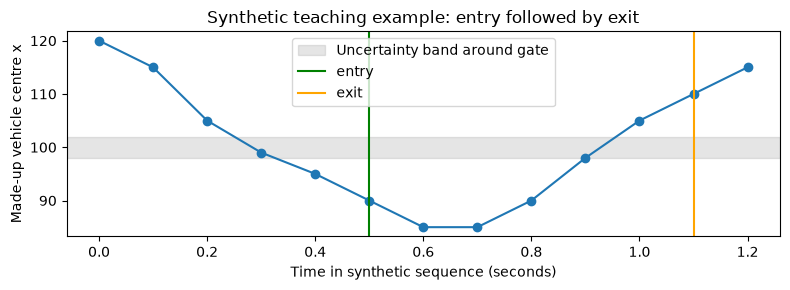

In [3]:
plt.figure(figsize=(8,3))
plt.plot([r['seconds'] for r in lesson], positions, marker='o')
plt.axhspan(98,102,color='gray',alpha=.2,label='Uncertainty band around gate')
for e in lesson_events:
    plt.axvline(e['video_time_seconds'],color='green' if e['event_type']=='entry' else 'orange',label=e['event_type'])
plt.xlabel('Time in synthetic sequence (seconds)'); plt.ylabel('Made-up vehicle centre x')
plt.title('Synthetic teaching example: entry followed by exit'); plt.legend(); plt.tight_layout(); plt.show()

## 2. What actually happened on the road recording

The street gate and settings were fixed before this run. Above-to-below the
horizontal cyan line is called entry for illustration; this road is not a real
parking entrance. The detector and tracker run on 25 frames, half a second apart.
No matching ground-truth crossings were supplied. A zero prediction does not
prove that no physical vehicles crossed.

In [4]:
RUN = 'GATE-VIDEO-20261024T231251838602Z'
folder = ROOT / 'experiments/results' / RUN
report = json.loads((folder/'run.json').read_text())
assert hashlib.sha256((ROOT/'src/smart_parking/flow.py').read_bytes()).hexdigest() == report['source_hashes']['src/smart_parking/flow.py']
summary = report['summary']
show_table([dict(measure='Processed real frames', value=summary['processed_frames']),
              dict(measure='Predicted entries', value=summary['flow_diagnostics']['counts']['entries']),
              dict(measure='Predicted exits', value=summary['flow_diagnostics']['counts']['exits']),
              dict(measure='Counting accuracy', value='NOT EVALUABLE: no human labels'),
              dict(measure='Export records agree', value=report['export_consistency_passed']),
              dict(measure='Runtime seconds', value=round(report['duration_seconds'],2))])

measure,value
Processed real frames,25
Predicted entries,0
Predicted exits,0
Counting accuracy,NOT EVALUABLE: no human labels
Export records agree,True
Runtime seconds,126.33


In [5]:
logs = [json.loads(line) for line in (folder/'video/detections.jsonl').read_text().splitlines()]
replay = GateCounter(**report['gate_config'])
replayed_events = []
for record in logs:
    output = replay.update(record['result']['detections'], record['video_time_seconds'])
    assert json.loads(json.dumps(output)) == record['result']['flow']
    replayed_events += output['events']
assert replayed_events == summary['flow_events']
print('All 25 saved tracking records replay exactly. This verifies reproducibility, not accuracy.')
print('Source: Street traffic, Editor, Wikimedia Commons, CC BY 3.0.')
print(report['source_attribution']['source_page'])

All 25 saved tracking records replay exactly. This verifies reproducibility, not accuracy.
Source: Street traffic, Editor, Wikimedia Commons, CC BY 3.0.
https://commons.wikimedia.org/wiki/File:Street_traffic.webm


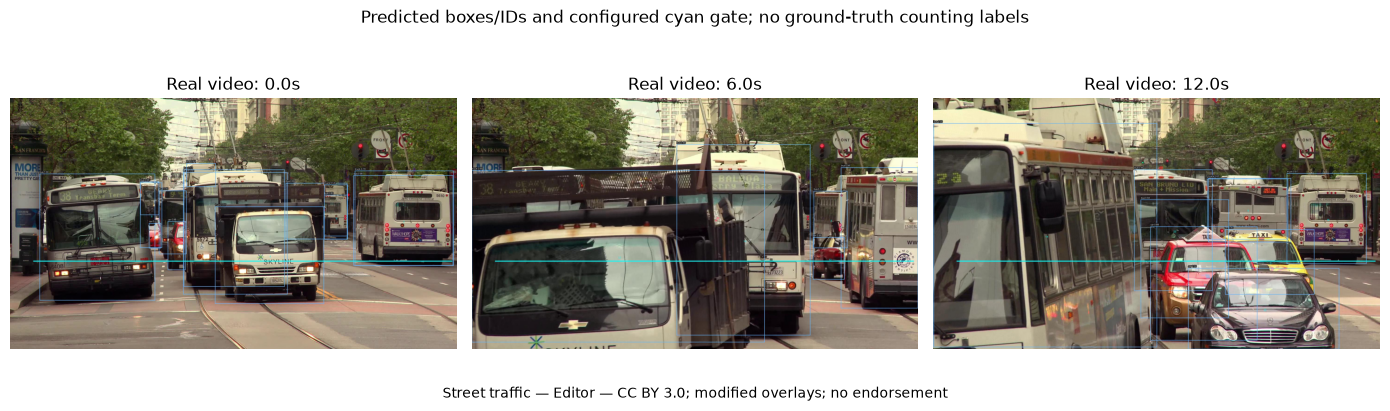

In [6]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for axis, record in zip(axes,[logs[0], logs[len(logs)//2], logs[-1]]):
    with Image.open(folder/'video'/f"frame_{record['frame']:07d}.jpg") as picture:
        axis.imshow(picture.copy())
    axis.set_title(f"Real video: {record['video_time_seconds']:.1f}s"); axis.axis('off')
fig.suptitle('Predicted boxes/IDs and configured cyan gate; no ground-truth counting labels')
fig.text(.5,.01,'Street traffic — Editor — CC BY 3.0; modified overlays; no endorsement',ha='center')
plt.tight_layout(rect=[0,.04,1,.93]); plt.show()

## 3. Why frequent observations matter

Imagine looking out a window only every two seconds. A vehicle might disappear
between glances. This cautious tracker drops its memory when the gap exceeds
0.75 seconds. We replayed the earlier two-second samples without changing that
rule; it reset on all 17 gaps and made no counts. That is abstention, not a
correct zero-traffic finding.

In [7]:
sparse = report['sparse_replay']['result']
print('Two-second replay gap resets:', sparse['gap_resets'])
print('Two-second replay predicted counts:', sparse['counts'])
print(report['sparse_replay']['interpretation'])
assert sparse['gap_resets'] == 17

Two-second replay gap resets: 17
Two-second replay predicted counts: {'entries': 0, 'exits': 0}
All17two-second gaps exceed0.75s; zero counts reflect abstention, not zero actual crossings


## Your learning checklist

- Explain why a vehicle detection, a gate crossing and parking occupancy differ.
- In the synthetic cell, move the gate endpoints or reverse `entry_direction`.
- Try a noisy centre near the gate. Explain why it should not count repeatedly.
- Describe why missing detections and occlusion can cause missed crossings.
- Before measuring real accuracy, reserve a different labelled video and freeze
  the method. Manually mark true crossing direction/time and identities.

The desktop video button does not yet have a graphical gate editor. The Python
API and `scripts/process_gate_video.py` support explicit local-file configuration.
See `docs/GATE_FLOW_GUIDE.md` for data locations, commands and limitations.
Student independent mastery has not been assessed.